In [2]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, BatchNormalization, Dropout
import matplotlib.pyplot as plt
import cv2
import numpy as np

In [3]:
!kaggle datasets download anokas/kuzushiji

Dataset URL: https://www.kaggle.com/datasets/anokas/kuzushiji
License(s): CC-BY-SA-4.0
100% 571M/571M [00:03<00:00, 172MB/s]



Dataset Used: https://www.kaggle.com/datasets/anokas/kuzushiji
##### Kuzushiji-49, as the name suggests, has 49 classes (28x28 grayscale, 270,912 images), is a much larger, but imbalanced dataset containing 48 Hiragana characters and one Hiragana iteration mark.

In [3]:
import zipfile
zip_ref = zipfile.ZipFile('./k49.zip')
zip_ref.extractall()
zip_ref.close()

##### We Loaded the dataset, and find that its shape is (232365,28,28) it means that it contains 232365 images each with a dimension of 28 and 28

In [5]:
train_images = np.load('./k49-train-imgs.npz')['arr_0']
train_labels = np.load('./k49-train-labels.npz')['arr_0']
train_images = train_images[...,np.newaxis]

In [6]:
test_images = np.load('./k49-test-imgs.npz')['arr_0']
test_labels = np.load('./k49-test-labels.npz')['arr_0']
test_images = test_images[...,np.newaxis]

In [7]:
#normalize
train_images=train_images.astype("float32")/255.0
test_images=test_images.astype("float32")/255.0

In [8]:
train_dataset = tf.data.Dataset.from_tensor_slices((train_images,train_labels))
train_dataset = train_dataset.shuffle(10000).batch(256).prefetch(tf.data.AUTOTUNE)

In [9]:
test_dataset = tf.data.Dataset.from_tensor_slices((test_images,test_labels))
test_dataset = test_dataset.shuffle(10000).batch(256).prefetch(tf.data.AUTOTUNE)

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def residual_block(x, filters, stride=1, dropout=0.0):

    shortcut = x

    # First convolution
    x = layers.Conv2D(
        filters,
        3,
        strides=stride,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Second convolution
    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters,
            1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Residual connection
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    if dropout > 0:
        x = layers.Dropout(dropout)(x)

    return x


def create_resnet_k49():

    inputs = layers.Input(shape=(28, 28, 1))

    # Initial feature extraction
    x = layers.Conv2D(
        64,
        3,
        padding="same",
        use_bias=False
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # 28x28
    x = residual_block(x, 64)
    x = residual_block(x, 64)

    # 14x14
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)

    # 7x7
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)

    # 4x4 approximately
    x = residual_block(x, 512, stride=2)
    x = residual_block(x, 512, dropout=0.2)

    # Global feature representation
    x = layers.GlobalAveragePooling2D()(x)

    # Classifier
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        49,
        activation="softmax"
    )(x)

    return Model(inputs, outputs)
model = create_resnet_k49()



In [11]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_k49.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

In [12]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 28,    │        576 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 28,    │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 28, 28,    │     36,864 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 28, 28,    │     36,864 │ re_lu_1[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 28, 28,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 28, 28,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 28, 28,    │     36,864 │ re_lu_3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 28, 28,    │          0 │ batch_normalizat

 Total params: 11,321,201 (43.19 MB)

 Trainable params: 11,311,601 (43.15 MB)

 Non-trainable params: 9,600 (37.50 KB)

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=1e-3,
        weight_decay=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(train_dataset,validation_data=test_dataset,epochs=40,callbacks=callbacks)
model.save('./hiragana_model_nano.keras')

KeyboardInterrupt: 

In [13]:
#Saving the model


In [1]:
import os
# ==========================================
# 6. EVALUATION (LOSS & ACCURACY PLOTS)
# ==========================================
# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

NameError: name 'plt' is not defined

In [15]:
model = keras.models.load_model('/content/hiragana_model_nano.keras')

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
from PIL import Image

def preprocess_image(image_path):
    # 1. Open as grayscale
    img = Image.open(image_path).convert("L")

    # 2. Convert to numpy
    img_array = np.array(img)

    # 3. Find non-white pixels
    # Adjust threshold if necessary
    mask = img_array < 240

    # 4. Find bounding box of character
    coords = np.argwhere(mask)

    if coords.size == 0:
        raise ValueError("No character detected")

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    # 5. Crop character
    cropped = img.crop((x_min, y_min, x_max + 1, y_max + 1))

    # 6. Add some padding
    w, h = cropped.size
    padding = int(max(w, h) * 0.2)

    canvas_size = max(w, h) + 2 * padding

    canvas = Image.new("L", (canvas_size, canvas_size), 255)

    x = (canvas_size - w) // 2
    y = (canvas_size - h) // 2

    canvas.paste(cropped, (x, y))

    # 7. Resize to model input
    canvas = canvas.resize((28, 28), Image.Resampling.LANCZOS)

    # 8. Convert to numpy
    img_array = np.array(canvas).astype("float32")/255.0
    img_array = 1-img_array 

    # 10. Add channel dimension
    img_array = np.expand_dims(img_array, axis=-1)

    # 11. Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    return img_array

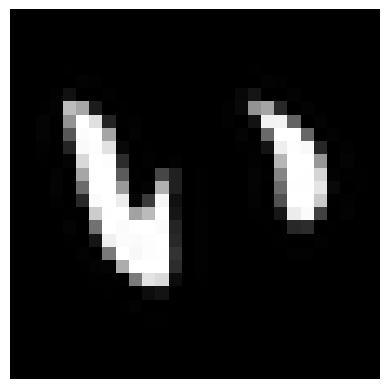

In [27]:
image = preprocess_image('/content/i.png')
# prediction = model.predict(image)

import matplotlib.pyplot as plt

plt.imshow(image[0, :, :, 0], cmap='gray')
plt.axis('off')
plt.show()


In [24]:
import pandas as pd
k49_classmap = pd.read_csv('/content/k49_classmap.csv')


In [28]:
pred = model.predict(image)
predicted_class = np.argmax(pred)
predicted_class

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


np.int64(47)

In [29]:
k49_classmap.iloc[predicted_class]

,47
index,47
codepoint,U+3093
char,ん
